<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">LSTM-Driven Tesla Stock Prediction: Modeling Financial Time Series</p>
<br />



<p>Pada notebook ini, kami akan melakukan time series forecasting terhadap data harga saham TSLA (Tesla Inc.) yang diambil dari Yahoo Finance. Proses dimulai dengan exploratory data analysis dan data preprocessing, kemudian dilanjutkan dengan pembangunan dan pelatihan beberapa model deep learning berbasis LSTM. Model-model yang akan digunakan meliputi: LSTM baseline, BiLSTM, CNN-LSTM, LSTM dengan tuning manual, serta LSTM dengan hyperparameter tuning otomatis. Setiap model akan dievaluasi menggunakan dua metrik utama, yaitu RMSE (Root Mean Squared Error) dan MAPE (Mean Absolute Percentage Error), untuk membandingkan performa prediksi antar model. Tujuan dari notebook ini adalah untuk menguji efektivitas berbagai arsitektur LSTM dalam memprediksi harga saham TSLA dan mengidentifikasi model terbaik berdasarkan hasil evaluasi.</p>

<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">Import Library</p>

In [ ]:
pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 9.9 MB/s eta 0:00:00


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotly.graph_objects as go
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import zscore
import tensorflow
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense, Bidirectional, Conv1D, MaxPooling1D, Flatten
from kerastuner.tuners import RandomSearch
from datetime import date
import warnings

warnings.filterwarnings('ignore')

<ipython-input-3-f9c387ee2979>:17: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch


<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">Import Dataset</p>

In [ ]:
data = yf.download('TSLA', start='2015-01-01', end='2025-05-21')

data

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2015-01-02,14.620667,14.883333,14.217333,14.858000,71466000
2015-01-05,14.006000,14.433333,13.810667,14.303333,80527500
2015-01-06,14.085333,14.280000,13.614000,14.004000,93928500
2015-01-07,14.063333,14.318667,13.985333,14.223333,44526000
2015-01-08,14.041333,14.253333,14.000667,14.187333,51637500
...,...,...,...,...,...
2025-05-14,347.679993,350.000000,337.000000,342.500000,136997300
2025-05-15,342.820007,346.140015,334.720001,340.339996,97882600


<h3>About the Dataset</h3>
<p>Data yang digunakan dalam proyek ini adalah data historis harga saham Tesla Inc. (TSLA) yang diambil dari Yahoo Finance menggunakan library yfinance. Dataset mencakup periode dari 1 Januari 2015 hingga 20 Mei 2025, dengan total 2611 baris data harian.</p>
<br />
<p>Setiap baris merepresentasikan data pasar saham TSLA pada satu hari perdagangan dan terdiri dari 5 kolom utama:</p>


1.   Close: Harga penutupan saham TSLA pada akhir hari perdagangan.
2.   High: Harga tertinggi saham TSLA yang tercatat pada hari itu.
3.   Low: Harga terendah saham TSLA yang tercatat pada hari itu.
4.   Open: Harga pembukaan saham TSLA pada awal hari perdagangan.
5.   Volume: Jumlah saham TSLA yang diperdagangkan selama hari tersebut.

In [ ]:
data = data[['Close']].copy()
data.dropna(inplace=True)

data.reset_index(inplace=True)
data.rename(columns={'index': 'Date'}, inplace=True)
data.columns = ['Date', 'Close']
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

- Mengambil kolom 'Close' saja karena kita hanya akan memprediksi harga penutupan saham TSLA.
- Menghapus nilai kosong (NaN) agar data bersih dan tidak error saat pelatihan model.
- Mereset index dan mengganti nama kolom waktu menjadi 'Date' agar lebih mudah dibaca dan dikelola.
- Mengonversi kolom 'Date' ke format datetime dan mengaturnya sebagai index supaya model mengenali urutan waktu secara kronologis dengan benar.

<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">Exploratory Data Analysis</p>

In [ ]:
data.describe()

,Close
count,2611.000000
mean,122.867415
std,118.676301
min,9.578000
25%,17.462333
50%,45.266666
75%,228.395004
max,479.859985


Dari ringkasan ini terlihat bahwa data harga penutupan memiliki sebaran yang luas, dengan nilai maksimum yang cukup tinggi dibandingkan median dan kuartil bawah. Hal ini mengindikasikan adanya kenaikan harga signifikan dalam beberapa periode waktu tertentu, dan dapat berdampak terhadap pemodelan time series karena adanya fluktuasi yang tajam.

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2611 entries, 2015-01-02 to 2025-05-20
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2611 non-null   float64
dtypes: float64(1)
memory usage: 40.8 KB


In [ ]:
data.isnull().sum()

,0
Close,0


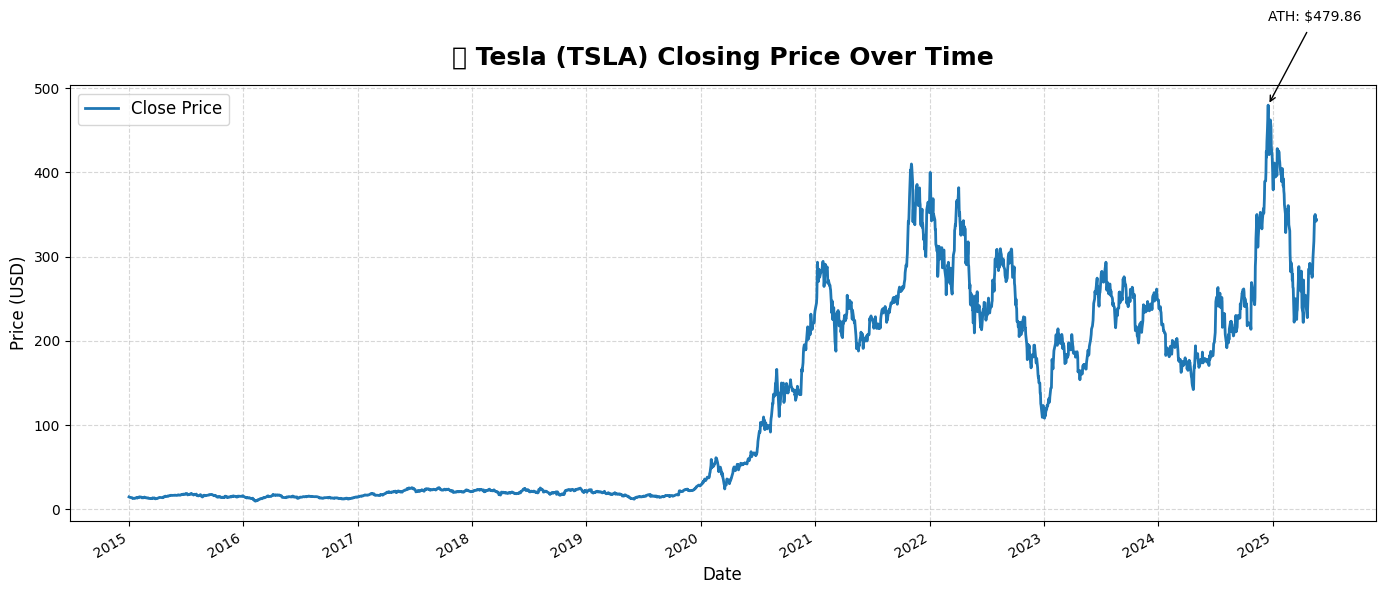

In [ ]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(data['Close'], label='Close Price', color='#1f77b4', linewidth=2)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.autofmt_xdate()

ax.set_title('📈 Tesla (TSLA) Closing Price Over Time', fontsize=18, fontweight='bold', pad=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Price (USD)', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=12)

max_price = data['Close'].max()
max_date = data['Close'].idxmax()
ax.annotate(f'ATH: ${max_price:.2f}',
            xy=(max_date, max_price),
            xytext=(max_date, max_price + 100),
            arrowprops=dict(facecolor='black', arrowstyle='->'),
            fontsize=10, backgroundcolor='white')

plt.tight_layout()
plt.show()

<h3>Visualisasi Harga Penutupan TSLA (2015–2025)</h3>
<h4>Insight dari Grafik:</h4>

- 2015–2019: Harga TSLA relatif stabil dan cenderung datar di bawah \$100. Hal ini mencerminkan fase awal pertumbuhan perusahaan, dengan produksi yang masih terbatas dan laba bersih yang belum konsisten.
- 2020: Terjadi lonjakan harga yang tajam. Hal ini kemungkinan besar disebabkan oleh keberhasilan peluncuran dan penjualan Tesla model 3 serta peningkatan kinerja keuangan dan masuknya Tesla ke indeks S&P 500 pada Desember 2020.
- 2021–2022: Harga terus meningkat dan mencapai all-time high (ATH) sekitar $479.86, yang mungkin dipicu oleh minat pasar terhadap saham teknologi dan energi terbarukan.
- 2022–2023: Terjadi penurunan dan volatilitas tajam, yang bisa dikaitkan dengan persaingan di industri EV yang semakin ketat dan serta sentimen pasar terhadap elon musk yang mengakuisisi twitter
- 2024–2025: Harga kembali mengalami fluktuasi dengan tren naik di awal 2025. Hal ini bisa jadi didorong oleh Peluncuran produk baru atau inovasi teknologi.


In [ ]:
rolling_mean = data['Close'].rolling(window=30).mean()
rolling_std = data['Close'].rolling(window=30).std()

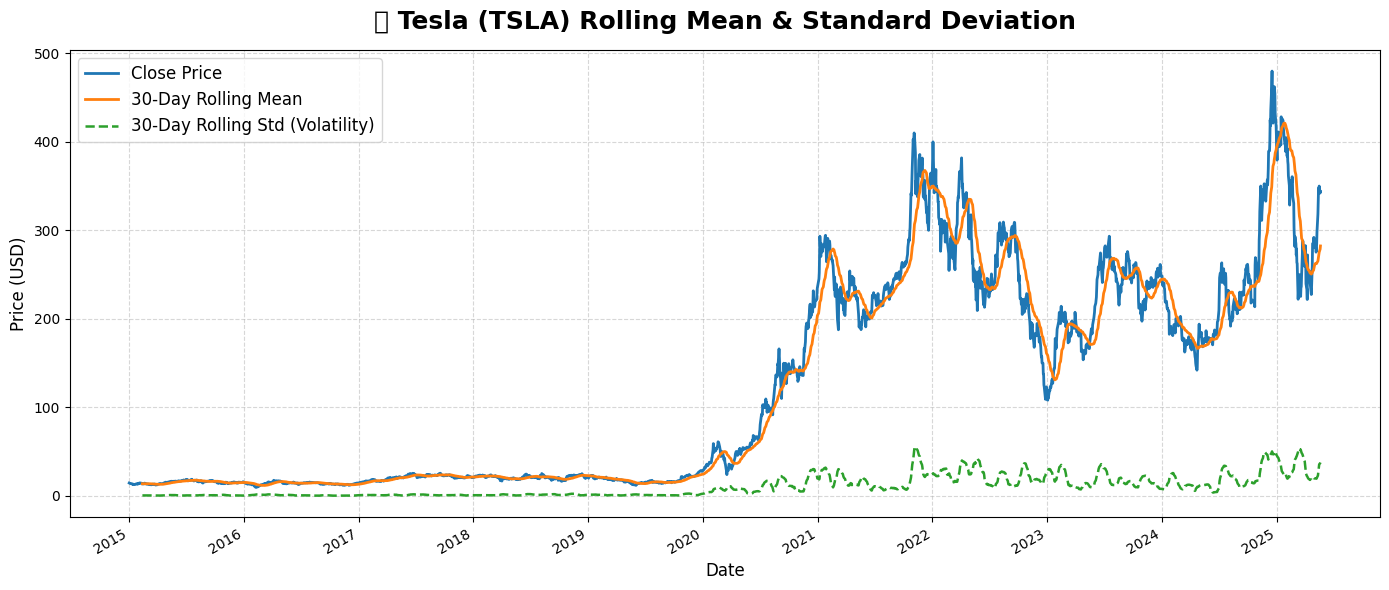

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(data['Close'], label='Close Price', color='#1f77b4', linewidth=2)
plt.plot(rolling_mean, label='30-Day Rolling Mean', color='#ff7f0e', linewidth=2)
plt.plot(rolling_std, label='30-Day Rolling Std (Volatility)', color='#2ca02c', linestyle='--', linewidth=1.8)

plt.title('📊 Tesla (TSLA) Rolling Mean & Standard Deviation', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gcf().autofmt_xdate()

plt.legend(fontsize=12, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


<h3>Analisis Rolling Mean dan Rolling Standard Deviation (Volatilitas)</h3>

Grafik di atas menampilkan pergerakan harga penutupan saham Tesla Inc. (TSLA) bersama dengan 30-day rolling mean (rata-rata bergerak 30 hari) dan 30-day rolling standard deviation (standar deviasi bergerak 30 hari atau volatilitas).

<h4>Insight dari Grafik:</h4>

- Selama periode 2015–2019, harga relatif stabil, dan baik rolling mean maupun rolling std juga mendatar rendah.
- Lonjakan harga mulai 2020 diikuti oleh kenaikan tajam pada rolling mean yang mengonfirmasi tren bullish serta kenaikan pada rolling std yang menunjukkan peningkatan volatilitas pasar.
- Selama periode puncak harga (ATH) dan penurunan tajam berikutnya, volatilitas meningkat drastis, terlihat dari gelombang pada garis hijau.
- Setiap periode kenaikan atau penurunan besar cenderung diikuti oleh peningkatan volatilitas, sesuai prinsip umum bahwa volatilitas tinggi sering menyertai ketidakpastian pasar.

In [ ]:
data['LogReturn'] = np.log(data['Close']) - np.log(data['Close'].shift(1))

Langkah ini menghitung log return harian dari harga penutupan saham TSLA, yaitu perubahan persentase harga dalam bentuk logaritmik dari hari ke hari.


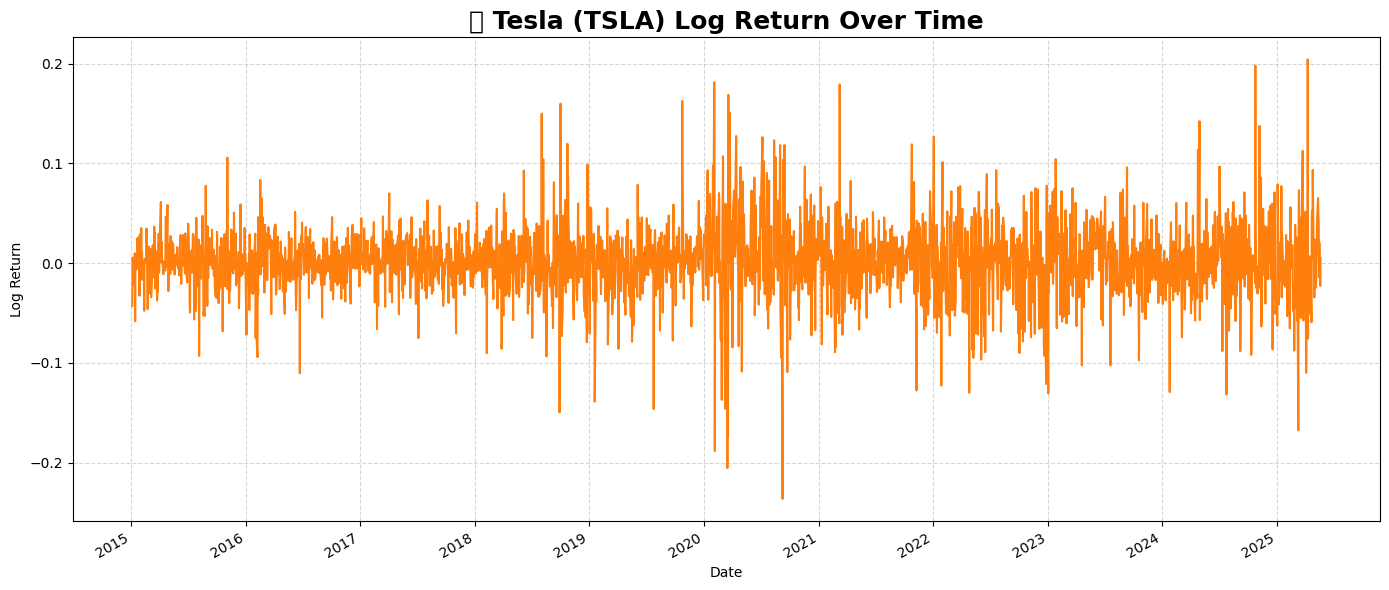

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(data['LogReturn'], color='#ff7f0e', linewidth=1.5)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gcf().autofmt_xdate()

plt.title('📉 Tesla (TSLA) Log Return Over Time', fontsize=18, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<h3>Visualisasi Log Return Harian Saham TSLA</h3>

Grafik di atas menunjukkan log return harian dari harga penutupan saham Tesla Inc. (TSLA) selama periode 2015 hingga 2025.

- Sumbu X: Tanggal (time axis) dari tahun 2015 sampai 2025.
- Sumbu Y: Nilai log return, yaitu perubahan logaritmik harga penutupan dari hari ke hari.
- Garis oranye: Menunjukkan pergerakan return harian saham TSLA dalam bentuk log, di mana nilai positif berarti harga naik dan nilai negatif berarti harga turun.

<h4>Insight dari Grafik:</h4>

- Fluktuasi log return terlihat semakin tinggi mulai 2020, mencerminkan meningkatnya volatilitas saham TSLA.
- Puncak-puncak positif dan negatif yang tajam menunjukkan hari-hari dengan lonjakan harga atau penurunan yang signifikan, seringkali berkaitan dengan earnings report, sentimen pasar dan kondisi makroekonomi global.

<h4>Mengapa menggunakan log return?</h4>

- Stabil secara statistik: Log return memiliki distribusi yang lebih mendekati normal dibandingkan return biasa (percentage change), terutama untuk data keuangan.
- Additivitas waktu: Log return bisa dijumlahkan dalam periode waktu berbeda (misal: log return mingguan = jumlah log return harian).
- Mengatasi skala besar: Cocok untuk data dengan rentang harga yang luas seperti saham TSLA.
<br />

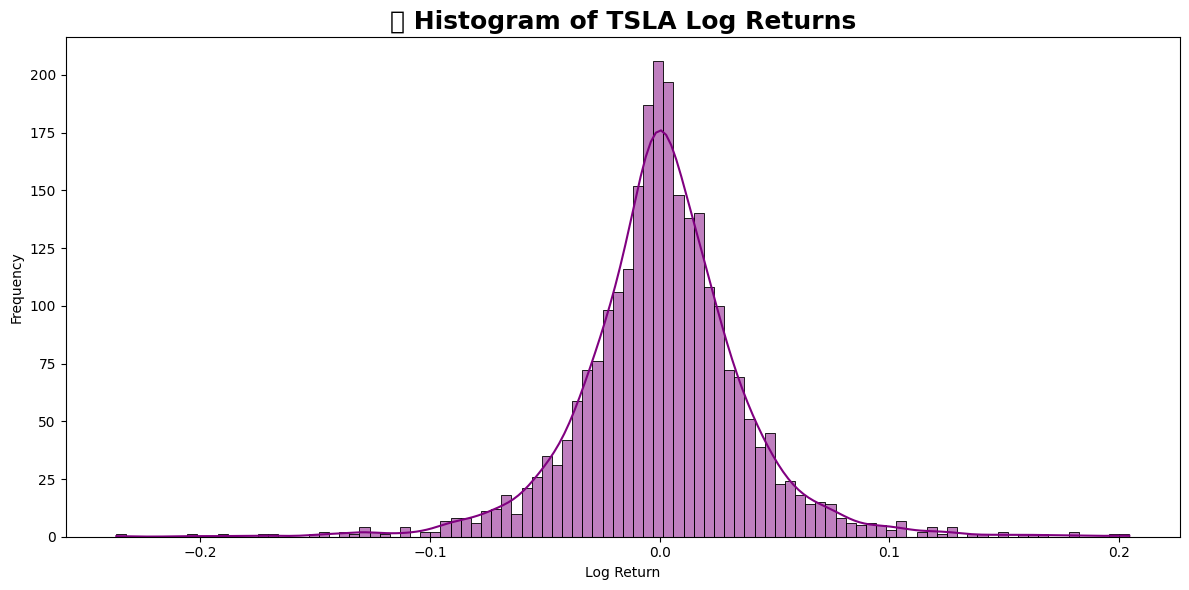

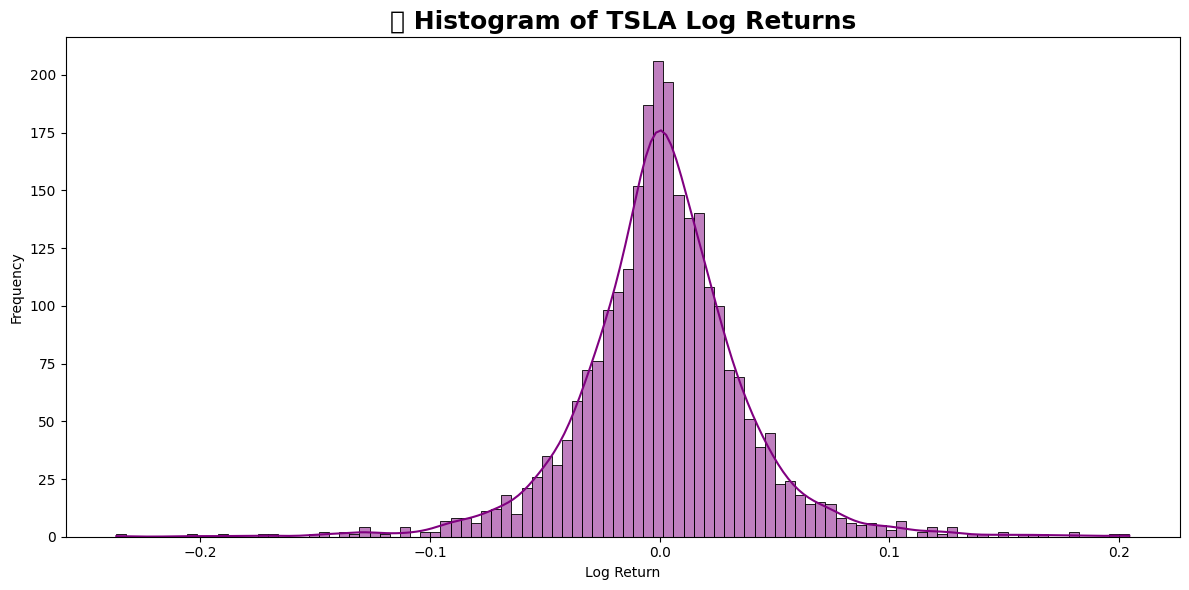

In [ ]:
plt.figure(figsize=(12, 6))
sns.histplot(data['LogReturn'].dropna(), bins=100, kde=True, color='purple')
plt.title('📊 Histogram of TSLA Log Returns', fontsize=18, fontweight='bold')
plt.xlabel('Log Return')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show(0)

<h3>Histogram Log Return Saham TSLA</h3>

Histogram log return saham TSLA menunjukkan bahwa sebagian besar return harian berada di sekitar nilai nol, yang berarti pergerakan harga harian cenderung kecil dan stabil. Distribusi terlihat simetris dan berbentuk seperti lonceng, menyerupai distribusi normal. Namun, tampak bahwa ujung distribusinya (tail) lebih panjang dari distribusi normal standar, mengindikasikan adanya fat tails. Ini berarti bahwa pergerakan harga ekstrem, baik naik maupun turun, meskipun jarang, tetap terjadi dan memiliki probabilitas yang lebih tinggi dibanding yang diperkirakan oleh distribusi normal. Pola seperti ini umum ditemukan pada data pasar keuangan, dan menjadi pertimbangan penting dalam membangun model prediksi, terutama dalam memperkirakan risiko dan volatilitas yang realistis.

In [ ]:
data.loc[data['LogReturn'].notnull(), 'Zscore'] = zscore(data['LogReturn'].dropna())
outliers = data[np.abs(data['Zscore']) > 3]

Kode tersebut digunakan untuk menghitung Z-score dari log return harian dan mengidentifikasi outlier, yaitu hari-hari dengan perubahan harga ekstrem yang memiliki Z-score lebih dari 3 atau kurang dari -3.

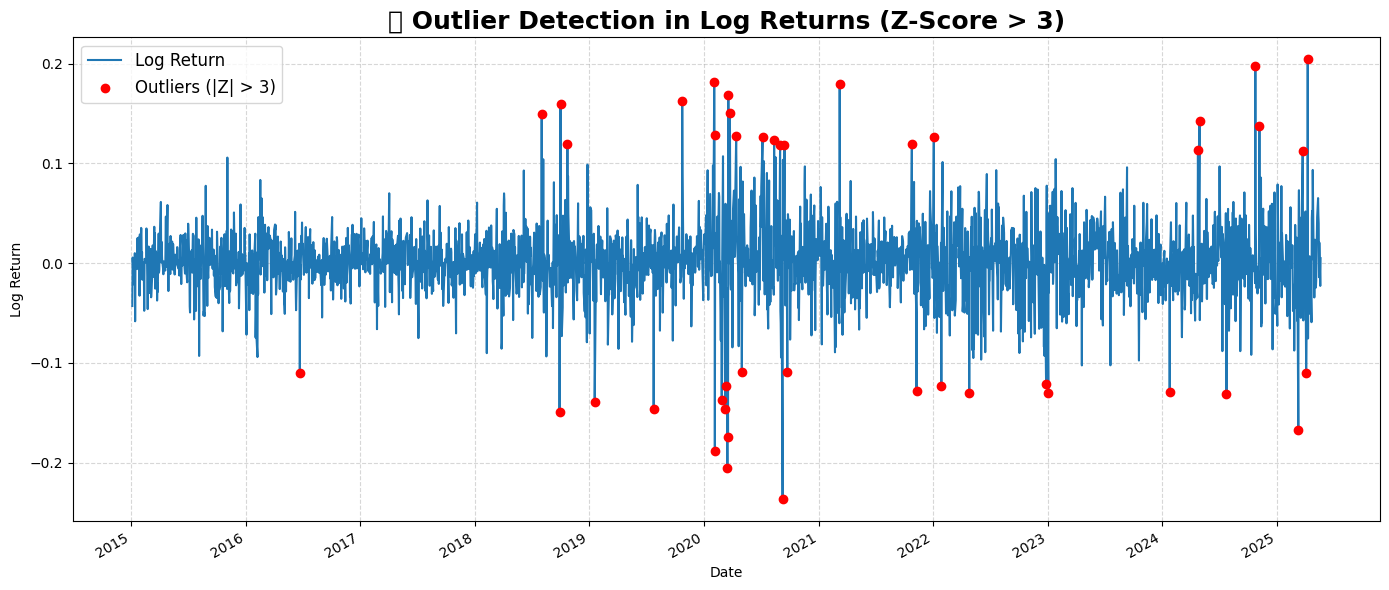

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(data['LogReturn'], label='Log Return', color='#1f77b4', linewidth=1.5)
plt.scatter(outliers.index, outliers['LogReturn'], color='red', label='Outliers (|Z| > 3)', zorder=5)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gcf().autofmt_xdate()

plt.title('🚨 Outlier Detection in Log Returns (Z-Score > 3)', fontsize=18, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<h3>Visualisasi Outlier pada Log Return Saham TSLA</h3>

Grafik di atas menampilkan log return harian saham TSLA dari tahun 2015 hingga 2025, dengan titik-titik outlier (pencilan) yang diidentifikasi berdasarkan Z-score > 3 atau < -3.

<h4>Penjelasan Komponen:</h4>

- Garis biru: Log return harian — menunjukkan perubahan harga dalam skala logaritmik dari satu hari ke hari berikutnya.
- Titik merah: Outlier — hari-hari di mana perubahan harga sangat ekstrem (baik naik maupun turun), dengan nilai Z-score absolut lebih dari 3.

<h4>Insight:</h4>

- Outlier tersebar secara tidak merata, dengan konsentrasi lebih tinggi pada periode 2020–2021, yang bertepatan dengan lonjakan popularitas dan harga TSLA, volatilitas pasar selama pandemi COVID-19, serta Event besar seperti stock split dan masuknya Tesla ke indeks S&P 500.
- Beberapa outlier juga muncul di tahun-tahun berikutnya (2022–2025), mengindikasikan bahwa volatilitas ekstrem tetap berlanjut meskipun tren harga berubah.
- Adanya outlier menunjukkan risiko tinggi yang harus dipertimbangkan dalam permodelan dan strategi investasi.
<br />

Visualisasi ini sangat berguna untuk mengidentifikasi hari-hari yang tidak biasa dan berpotensi mengganggu model prediktif. Langkah selanjutnya bisa mencakup penghapusan, penyesuaian, atau perlakuan khusus terhadap outlier tergantung tujuan analisis atau model yang akan dibangun.

<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">Data Preprocessing and Feature Engineering</p>

<h4>Splitting the Dataset<h4>

membagi data harga penutupan TSLA menjadi data pelatihan (2015–2023), validasi (2024), dan pengujian (2025) berdasarkan rentang waktu untuk keperluan training dan evaluasi model time series secara berurutan.

In [ ]:
train_data = data.loc['2015-01-01':'2023-12-31', ['Close']]
val_data   = data.loc['2024-01-01':'2024-12-31', ['Close']]
test_data  = data.loc['2025-01-01':, ['Close']]

<h4>Normalisasi Data dengan MinMaxScale</h4>

In [ ]:
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)
val_scaled   = scaler.transform(val_data)
test_scaled  = scaler.transform(test_data)
#show summary
print(f"Train Shape: {train_scaled.shape}, Val Shape: {val_scaled.shape}, Test Shape: {test_scaled.shape}")

Train Shape: (2264, 1), Val Shape: (252, 1), Test Shape: (95, 1)


<h4>Membuat Sequence Data untuk Input Model</h4>

In [ ]:
def create_sequences(dataset, lookback=60):
    X, y = [], []
    for i in range(lookback, len(dataset)):
        X.append(dataset[i-lookback:i])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)
    #show the result
    print(f"X shape: {X.shape}, y shape: {y.shape}")

<h4>Membentuk Input Sequence dan Reshape untuk Model LSTM</h4>

In [ ]:
lookback = 60
X_train, y_train = create_sequences(train_scaled, lookback)
X_val, y_val     = create_sequences(val_scaled, lookback)
X_test, y_test   = create_sequences(test_scaled, lookback)

X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_val   = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

#show
print(f"Train Shape: {X_train.shape}, Val Shape: {X_val.shape}, Test Shape: {X_test.shape}")

Train Shape: (2204, 60, 1), Val Shape: (192, 60, 1), Test Shape: (35, 60, 1)


In [ ]:
# split = int(0.8 * len(X))
# X_train, y_train = X[:split], y[:split]
# X_test, y_test = X[split:], y[split:]

NameError: name 'X' is not defined

In [ ]:
print("Shapes:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}, y_val  : {y_val.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape}")

Shapes:
X_train: (2204, 60, 1), y_train: (2204,)
X_val  : (192, 60, 1), y_val  : (192,)
X_test : (35, 60, 1), y_test : (35,)


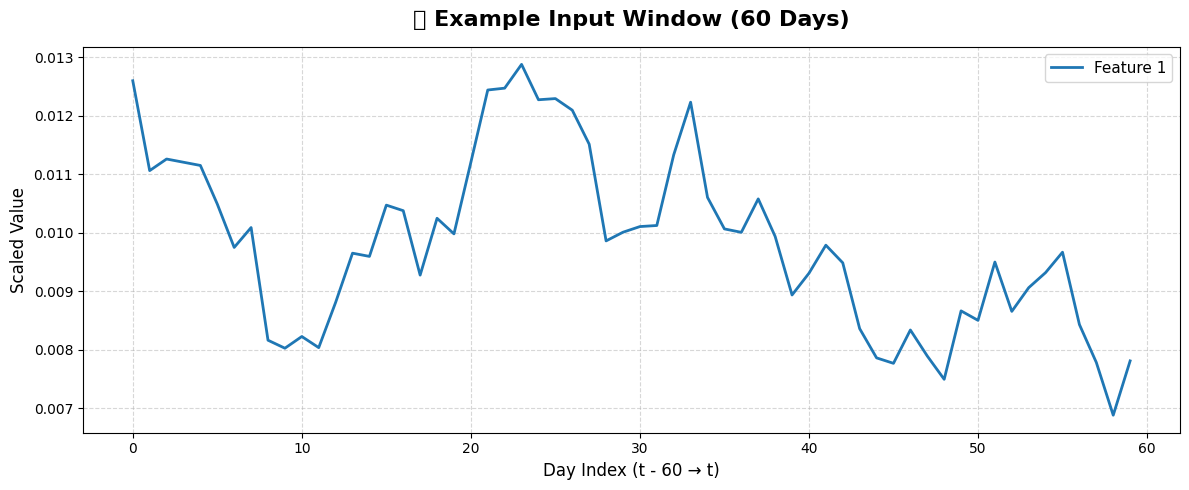

In [ ]:
n_features = X_train.shape[2]
colors = cm.get_cmap('tab10', n_features).colors
linestyles = ['-', '--', '-.', ':'] * (n_features // 4 + 1)

plt.figure(figsize=(12, 5))
for i in range(n_features):
    plt.plot(X_train[0][:, i],
             label=f'Feature {i+1}',
             linewidth=2,
             color=colors[i],
             linestyle=linestyles[i])

plt.title('📦 Example Input Window (60 Days)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Day Index (t - 60 → t)', fontsize=12)
plt.ylabel('Scaled Value', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

<h3>Visualisasi Contoh Input Window (60 Hari)</h3>

Grafik di atas menunjukkan contoh input window sepanjang 60 hari terakhir (lookback = 60) yang digunakan sebagai fitur input untuk model LSTM.

<h4>Penjelasan:</h4>

- Sumbu X: Indeks hari dari t-60 hingga t (urutan waktu dalam window).
- Sumbu Y: Nilai harga penutupan yang telah dinormalisasi (scaled) menggunakan MinMaxScaler.
- Garis biru: Mewakili pola pergerakan harga dalam 60 hari terakhir — ini adalah satu contoh dari input yang akan diberikan ke model untuk memprediksi harga pada hari ke-61.

<p style="background-color:#f0efeb;font-family:robotto;color:#682F2F;font-size:150%;text-align:center;border-radius:6px 6px;">Modeling</p>

In [ ]:
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ReduceLROnPlateau(patience=5, factor=0.5, min_lr=1e-5)
]

Dalam proyek ini, dilakukan forecasting harga penutupan saham Tesla Inc. (TSLA) menggunakan berbagai varian model berbasis Long Short-Term Memory (LSTM), yaitu:



### 1. LSTM Baseline

<h4>Arsitektur</h4>


```
LSTM(50 units) → Dense(1)

```

Model dasar ini terdiri dari satu lapisan LSTM dengan 50 unit neuron yang langsung diikuti oleh lapisan Dense berisi satu neuron output.
Model ini menggunakan:
- Optimizer: Adam
- Loss Function: Mean Squared Error (MSE)
- Epochs: 20
- Batch Size: 32

Model ini bertindak sebagai benchmark awal, sederhana namun cukup kuat untuk mengenali pola jangka pendek dalam data time series.

In [ ]:
baseline_model = Sequential([
    LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1)
])

baseline_model.compile(optimizer='adam', loss='mse')
baseline_history = baseline_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.0563 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 2/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0013 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 3/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 4/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0010 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 5/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0010 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 6/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 9.2711e-04 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 7/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.9253e-04 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 8/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7.1260e-04 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 9/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.0602e-04 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 10/20

In [ ]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

### 2. Bidirectional LSTM (BiLSTM)

<h4>Arsitektur</h4>


```
Bidirectional(LSTM(64 units)) → Dropout(0.2) → Dense(1)

```

Model ini menggunakan Bidirectional LSTM, yang berarti sequence dibaca dari dua arah: maju (past→future) dan mundur (future→past).
Ini membuat model lebih peka terhadap konteks global dalam window 60 hari.

Fitur tambahan:
- Dropout 0.2 untuk mengurangi overfitting.
- Ukuran LSTM lebih besar (64 unit) dibanding baseline.

Training condition:
- Epochs: 30
- Batch Size: 32

Model ini cocok untuk mengenali pola time series yang tidak selalu bersifat progresif satu arah.

In [ ]:
bilstm_model = Sequential([
    Bidirectional(LSTM(64, return_sequences=False), input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(1)
])

bilstm_model.compile(optimizer='adam', loss='mse')
bilstm_history = bilstm_model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0319 - val_loss: 0.0065 - learning_rate: 0.0010
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0027 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0018 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0017 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0017 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0015 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 7/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 8/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0011 - val_loss: 0.0021 - learning_rate: 0.0010
Epoch 9/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0011 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 10/30
69/69 ━━━━━━━

In [ ]:
bilstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,765 (397.52 KB)

 Trainable params: 33,921 (132.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 67,844 (265.02 KB)

### 3. CNN-LSTM

<h4>Arsitektur</h4>


```
Conv1D(64 filters, kernel size=3, relu) → MaxPooling1D(pool_size=2) → LSTM(50 units) → Dense(1)

```

Model ini menggabungkan CNN untuk ekstraksi fitur lokal dari data time series, lalu mengalirkan hasilnya ke LSTM untuk menangkap dependensi temporal.

Komponen penting:
- Conv1D: Menangkap pola-pola lokal jangka pendek dalam window.
- MaxPooling1D: Mengurangi dimensi dan menyaring noise.
- LSTM(50): Menangkap hubungan waktu dari fitur hasil ekstraksi CNN.

Training condition:
- Epochs: 30
- Batch Size: 32

Model ini ideal jika ada pola jangka pendek berulang dalam data historis harga saham.

In [ ]:
cnn_lstm_model = Sequential([
    Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    MaxPooling1D(pool_size=2),
    LSTM(50),
    Dense(1)
])

cnn_lstm_model.compile(optimizer='adam', loss='mse')
cnn_lstm_history = cnn_lstm_model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0389 - val_loss: 0.0062 - learning_rate: 0.0010
Epoch 2/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0014 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 3/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 4/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 9.4346e-04 - val_loss: 0.0029 - learning_rate: 0.0010
Epoch 5/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.3702e-04 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 6/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.2926e-04 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 7/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 8.1462e-04 - val_loss: 0.0026 - learning_rate: 0.0010
Epoch 8/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.9736e-04 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 9/30
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.3069e-04 - val_loss: 0.0018 - learning_rate: 0.0010
Epo

In [ ]:
cnn_lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 58, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,923 (273.14 KB)

 Trainable params: 23,307 (91.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 46,616 (182.10 KB)

### 4. Manual Tunned LSTM

<h4>Arsitektur</h4>


```
LSTM(128 units) → Dropout(0.3) → Dense(1)

```

Model ini merupakan hasil dari penyesuaian manual terhadap parameter arsitektur dan pelatihan.

Perbedaan dari baseline:
- Jumlah unit LSTM ditingkatkan menjadi 128, memungkinkan model menangkap pola yang lebih kompleks.
- Dropout lebih tinggi (0.3) untuk menangkal overfitting.
- Learning rate diturunkan menjadi 0.0005 agar pelatihan lebih stabil.
- Batch size lebih besar (64) dan jumlah epoch ditingkatkan (50) untuk memberikan waktu pelatihan yang cukup.

Model ini adalah hasil eksperimen yang bertujuan mengoptimalkan performa tanpa hyperparameter tuning otomatis.

In [ ]:
tuned_lstm_model = Sequential([
    LSTM(128, return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.3),
    Dense(1)
])

tuned_lstm_model.compile(optimizer=tensorflow.keras.optimizers.Adam(learning_rate=0.0005), loss='mse')
tuned_lstm_history = tuned_lstm_model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_val, y_val), callbacks=callbacks)

Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0584 - val_loss: 0.0045 - learning_rate: 5.0000e-04
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0030 - val_loss: 0.0040 - learning_rate: 5.0000e-04
Epoch 3/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0029 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 4/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0021 - val_loss: 0.0041 - learning_rate: 5.0000e-04
Epoch 5/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0022 - val_loss: 0.0042 - learning_rate: 5.0000e-04
Epoch 6/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0020 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 7/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0018 - val_loss: 0.0031 - learning_rate: 5.0000e-04
Epoch 8/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0017 - val_loss: 0.0032 - learning_rate: 5.0000e-04
Epoch 9/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0015 - val_loss: 0.0032 - learning_rate: 5.

In [ ]:
tuned_lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 128)            │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 200,069 (781.52 KB)

 Trainable params: 66,689 (260.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 133,380 (521.02 KB)

In [ ]:
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Baseline Model",
        "BiLSTM Model",
        "CNN-LSTM Model",
        "Tuned LSTM Model"
    )
)

fig.add_trace(go.Scatter(y=baseline_history.history['loss'], name='Train Loss', mode='lines'), row=1, col=1)
fig.add_trace(go.Scatter(y=baseline_history.history['val_loss'], name='Val Loss', mode='lines'), row=1, col=1)

fig.add_trace(go.Scatter(y=bilstm_history.history['loss'], name='Train Loss', mode='lines', showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(y=bilstm_history.history['val_loss'], name='Val Loss', mode='lines', showlegend=False), row=1, col=2)

fig.add_trace(go.Scatter(y=cnn_lstm_history.history['loss'], name='Train Loss', mode='lines', showlegend=False), row=2, col=1)
fig.add_trace(go.Scatter(y=cnn_lstm_history.history['val_loss'], name='Val Loss', mode='lines', showlegend=False), row=2, col=1)

fig.add_trace(go.Scatter(y=tuned_lstm_history.history['loss'], name='Train Loss', mode='lines', showlegend=False), row=2, col=2)
fig.add_trace(go.Scatter(y=tuned_lstm_history.history['val_loss'], name='Val Loss', mode='lines', showlegend=False), row=2, col=2)

fig.update_layout(
    title_text="📊 Training vs Validation Loss per Model",
    height=800,
    width=1200,
    template='plotly_white',
    hovermode='x unified',
    legend=dict(x=0.5, y=1.12, xanchor='center', orientation='h', font=dict(size=12)),
)

fig.update_xaxes(title_text="Epoch", row=1, col=1)
fig.update_xaxes(title_text="Epoch", row=1, col=2)
fig.update_xaxes(title_text="Epoch", row=2, col=1)
fig.update_xaxes(title_text="Epoch", row=2, col=2)

fig.update_yaxes(title_text="Loss", row=1, col=1)
fig.update_yaxes(title_text="Loss", row=1, col=2)
fig.update_yaxes(title_text="Loss", row=2, col=1)
fig.update_yaxes(title_text="Loss", row=2, col=2)

fig.show()

### Analisis Training vs Validation Loss per Model

<h4>1. Baseline Model</h4>

- Train loss menurun dengan cepat dan stabil pada nilai rendah.
- Val loss juga menurun, namun fluktuatif setelah beberapa epoch.

 Kesimpulan: Model belajar cukup baik, tetapi menunjukkan sedikit overfitting ringan, karena val loss tidak konsisten.

<br/>

<h4>2. BiLSTM Model</h4>

- Train loss terus menurun secara stabil.
- Val loss juga menurun namun tidak sehalus train loss — sedikit fluktuasi.

Kesimpulan: Model memiliki kemampuan generalisasi yang baik, namun masih menunjukkan variasi val loss, mungkin karena model lebih kompleks (dua arah).

<br/>

<h4>3. CNN-LSTM Model</h4>

- Train loss menurun dengan cepat, namun berfluktuasi tajam pada epoch awal.
- Val loss cukup rendah dan stabil, lebih halus dari train loss.

Kesimpulan: Model berhasil menangkap pola dengan baik, tetapi fluktuasi train loss menunjukkan ketidakstabilan pelatihan awal, mungkin karena arsitektur yang lebih kompleks.

<br/>

<h4>4. Tuned LSTM Model</h4>

- Train loss sangat rendah dan stabil sejak awal.
- Val loss juga rendah dan konsisten sejajar dengan train loss.

Kesimpulan: Ini adalah model dengan kinerja paling stabil dan akurat, menunjukkan sedikit atau tidak ada overfitting, berkat tuning manual yang efektif (lebih banyak unit, dropout, dan learning rate kecil).

<br />

<h3>Kesimpulan Umum</h3>

- Semua model menunjukkan konvergensi (berhasil belajar), tetapi tingkat stabilitas dan generalisasi berbeda-beda.
- Tuned LSTM Model memiliki performa paling konsisten dan seimbang antara train dan validation loss.
- BiLSTM dan CNN-LSTM memiliki potensi bagus tetapi perlu perhatian lebih terhadap fluktuasi untuk menghindari overfitting atau pelatihan tidak stabil.
- Baseline model cukup baik sebagai pembanding, namun tidak seefektif model yang dituning.

### 5. LSTM dengan Hyperparameter Tuning

Function dibawah digunakan untuk membuat model LSTM yang arsitekturnya disesuaikan secara otomatis berdasarkan kombinasi hyperparameter (jumlah unit, dropout, dan learning rate) dalam proses tuning menggunakan Keras Tuner.

In [ ]:
def build_model(hp):
    model = Sequential()

    model.add(LSTM(
        units=hp.Int('units', min_value=32, max_value=256, step=32),
        input_shape=(X_train.shape[1], X_train.shape[2])
    ))

    model.add(Dropout(hp.Float('dropout', 0.1, 0.5, step=0.1)))

    model.add(Dense(1))

    model.compile(
        optimizer=tensorflow.keras.optimizers.Adam(
            learning_rate=hp.Choice('lr', [1e-2, 1e-3, 5e-4, 1e-4])
        ),
        loss='mse'
    )

    return model

Menjalankan hyperparameter tuning untuk model LSTM menggunakan RandomSearch dari Keras Tuner, dengan tujuan meminimalkan val_loss melalui eksplorasi hingga 10 kombinasi model, lalu melatih masing-masing selama 30 epoch menggunakan data pelatihan dan validasi.

In [ ]:
tuner = RandomSearch(
    build_model,
    objective='val_loss',
    max_trials=10,
    executions_per_trial=1,
    directory='tsla_tuner',
    project_name='lstm_tuning'
)

tuner.search_space_summary()

tuner.search(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)]
)

Trial 10 Complete [00h 00m 07s]
val_loss: 0.0029474887996912003

Best val_loss So Far: 0.0008188807405531406
Total elapsed time: 00h 02m 57s


In [ ]:
best_hp = tuner.get_best_hyperparameters(1)[0]

print("Best Hyperparameters Found:")
print(f"Units       : {best_hp.get('units')}")
print(f"Dropout     : {best_hp.get('dropout')}")
print(f"LearningRate: {best_hp.get('lr')}")

Best Hyperparameters Found:
Units       : 96
Dropout     : 0.1
LearningRate: 0.01


Training model terbaik yang dihasilkan dari proses tuning menggunakan 50 epochs dengan early stopping dan penurunan learning rate otomatis untuk mengoptimalkan performa dan mencegah overfitting.

In [ ]:
best_model = tuner.hypermodel.build(best_hp)

best_model_history = best_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[
        EarlyStopping(patience=10, restore_best_weights=True),
        ReduceLROnPlateau(patience=5, factor=0.5)
    ]
)

Epoch 1/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0528 - val_loss: 0.0028 - learning_rate: 0.0100
Epoch 2/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 9.6514e-04 - val_loss: 0.0019 - learning_rate: 0.0100
Epoch 3/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 8.8672e-04 - val_loss: 0.0018 - learning_rate: 0.0100
Epoch 4/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 8.9786e-04 - val_loss: 0.0018 - learning_rate: 0.0100
Epoch 5/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.5145e-04 - val_loss: 0.0016 - learning_rate: 0.0100
Epoch 6/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.5985e-04 - val_loss: 0.0014 - learning_rate: 0.0100
Epoch 7/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.8548e-04 - val_loss: 0.0014 - learning_rate: 0.0100
Epoch 8/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 6.6564e-04 - val_loss: 0.0020 - learning_rate: 0.0100
Epoch 9/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.7252e-04 - val_loss: 0.0018 - learning_rate: 0.

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    y=best_model_history.history['loss'],
    mode='lines',
    name='Train Loss'
))

fig.add_trace(go.Scatter(
    y=best_model_history.history['val_loss'],
    mode='lines',
    name='Validation Loss'
))

fig.update_layout(
    title='📈 Training vs Validation Loss - Best Tuned Model',
    xaxis_title='Epoch',
    yaxis_title='MSE Loss',
    template='plotly_white',
    width=1000,
    height=500,
    hovermode='x unified',
    legend=dict(font=dict(size=12))
)

fig.show()

<h3>Training vs Validation Loss – Best Tuned Model</h3>

Grafik di atas menunjukkan perbandingan loss (MSE) antara data pelatihan dan data validasi selama pelatihan model terbaik hasil hyperparameter tuning.

<h4>Insight:</h4>
- Train loss (garis biru) menurun dengan cepat dan stabil, lalu berada di kisaran rendah (~0.002).
- Validation loss (garis merah) fluktuatif, namun tetap berada di rentang yang sebanding dengan train loss.
- Tidak ada tanda overfitting signifikan, karena gap antara train dan val loss tetap kecil.
- Fluktuasi pada validation loss wajar terjadi dalam data pasar saham yang sangat volatil.

<br />

Model hasil tuning menunjukkan performa yang baik dan generalisasi yang stabil, dengan training dan validation loss rendah serta tidak menyimpang jauh, menandakan bahwa kombinasi hyperparameter yang dipilih cukup optimal.

###  Evaluasi Performa Model pada Data Tahun 2025

Menentukan Tanggal Awal Window untuk Prediksi Tahun 2025

In [ ]:
target_date = pd.Timestamp('2025-01-01')
business_days = pd.bdate_range(end=target_date - pd.Timedelta(days=1), periods=60)

start_date = business_days[0]
print("Mulai test_data dari:", start_date)

Mulai test_data dari: 2024-10-09 00:00:00


In [ ]:
test_data = data.loc['2024-10-09':'2025-05-20', ['Close']]

Melakukan prediksi menggunakan semua model

In [ ]:
y_test_pred_baseline = baseline_model.predict(X_test).flatten()
y_test_pred_bilstm   = bilstm_model.predict(X_test).flatten()
y_test_pred_cnnlstm  = cnn_lstm_model.predict(X_test).flatten()
y_test_pred_tuned    = tuned_lstm_model.predict(X_test).flatten()
y_test_pred_best     = best_model.predict(X_test).flatten()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step


In [ ]:
y_test_true_inv   = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_baseline   = scaler.inverse_transform(y_test_pred_baseline.reshape(-1, 1)).flatten()
y_pred_bilstm     = scaler.inverse_transform(y_test_pred_bilstm.reshape(-1, 1)).flatten()
y_pred_cnnlstm    = scaler.inverse_transform(y_test_pred_cnnlstm.reshape(-1, 1)).flatten()
y_pred_tuned      = scaler.inverse_transform(y_test_pred_tuned.reshape(-1, 1)).flatten()
y_pred_best       = scaler.inverse_transform(y_test_pred_best.reshape(-1, 1)).flatten()

Kode diatas digunakan untuk mengubah kembali (inverse transform) nilai hasil prediksi dan nilai target y_test dari skala normalisasi [0, 1] ke skala asli harga saham menggunakan MinMaxScaler, agar hasil prediksi dapat dibandingkan secara realistis dalam satuan USD.

### Cara Kerja Prediksi LSTM dengan Lookback = 60

Pada proyek ini, saya menggunakan pendekatan sliding window dengan parameter lookback = 60, yang berarti setiap input ke model berisi data harga penutupan selama 60 hari terakhir untuk memprediksi harga penutupan pada hari ke-61.

<br />

<h3>Pembentukan Input dan Target</h3>

Data time series dibentuk menggunakan fungsi create_sequences(), di mana:
- Input (X) adalah array berdimensi (samples, 60, 1) yang merepresentasikan 60 hari berturut-turut harga penutupan saham TSLA.
- Target (y) adalah harga penutupan pada hari ke-61 (output yang ingin diprediksi oleh model).

Setiap baris input bisa diilustrasikan sebagai berikut:

$$
X = [\text{Close}_{t-60}, \text{Close}_{t-59}, \dots, \text{Close}_{t-1}] \Rightarrow y = \text{Close}_t
$$

Proses ini dilakukan secara bergulir (sliding window) di sepanjang dataset.

<br />

<h3>Proses Prediksi oleh LSTM</h3>

Model LSTM dilatih untuk mengenali pola atau tren dalam 60 hari terakhir agar mampu memperkirakan harga pada hari berikutnya.  
Arsitektur LSTM sangat cocok untuk time series karena dapat **mengingat informasi jangka panjang** dan menangani dependensi temporal.

<br />

<h3>Prediksi pada Data Tahun 2025</h3>

Pada saat pengujian:
- Input X_test sudah dibentuk dari data 60 hari sebelum titik prediksi pada tahun 2025.
- Setiap prediksi yang dihasilkan mewakili estimasi harga penutupan untuk hari ke-61 dari window input tersebut.

Dengan pendekatan ini, model diharapkan mampu memberikan prediksi yang berdasarkan konteks historis 60 hari terakhir, mencerminkan tren, momentum, atau pola teknikal yang relevan.

<h3>Visualisasi Hasil Prediksi Harga Saham TSLA vs Data Aktual (2025)</h3>

In [ ]:
dates = test_data.index[lookback:]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=dates, y=y_test_true_inv, mode='lines', name='Actual Price (TSLA)',
    line=dict(color='black', width=2)
))

fig.add_trace(go.Scatter(x=dates, y=y_pred_baseline, mode='lines', name='Baseline'))
fig.add_trace(go.Scatter(x=dates, y=y_pred_bilstm, mode='lines', name='BiLSTM'))
fig.add_trace(go.Scatter(x=dates, y=y_pred_cnnlstm, mode='lines', name='CNN-LSTM'))
fig.add_trace(go.Scatter(x=dates, y=y_pred_tuned, mode='lines', name='Tuned LSTM'))
fig.add_trace(go.Scatter(x=dates, y=y_pred_best, mode='lines', name='Best Tuned'))

fig.update_layout(
    title='📊 TSLA Price Prediction vs Actual (2025)',
    xaxis_title='Date',
    yaxis_title='Price (USD)',
    hovermode='x unified',
    template='plotly_white',
    width=1200,
    height=600,
    legend=dict(font=dict(size=11)),
    xaxis=dict(
        tickformat='%b %d',
        dtick='604800000',
        tickangle=45
    )
)

fig.show()

In [ ]:
def evaluate_model_rmse_mape(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return rmse, mape

In [ ]:
models = {
    'Baseline': y_pred_baseline,
    'BiLSTM': y_pred_bilstm,
    'CNN-LSTM': y_pred_cnnlstm,
    'Tuned LSTM': y_pred_tuned,
    'Best Tuned': y_pred_best
}

In [ ]:
results = []

for name, y_pred in models.items():
    rmse, mape = evaluate_model_rmse_mape(y_test_true_inv, y_pred)
    results.append([name, rmse, mape])

metrics_df = pd.DataFrame(results, columns=['Model', 'RMSE', 'MAPE (%)'])
metrics_df = metrics_df.sort_values(by='RMSE')

### Evaluasi Kinerja Model Berdasarkan RMSE dan MAPE

Tabel di bawah menampilkan performa lima model prediksi harga saham TSLA pada data tahun 2025 berdasarkan dua metrik evaluasi utama:

<br />

<h4>Evaluation Metrics:</h4>

- RMSE (Root Mean Squared Error): Mengukur besar rata-rata galat kuadrat dalam satuan dolar. Nilai lebih rendah berarti prediksi lebih dekat ke nilai aktual.
- MAPE (Mean Absolute Percentage Error): Mengukur kesalahan dalam bentuk persentase relatif terhadap harga aktual. Nilai lebih rendah menunjukkan akurasi yang lebih tinggi.

<br />

<h4>Kesimpulan</h4>

- CNN-LSTM menunjukkan performa terbaik dengan error terkecil, menunjukkan bahwa kombinasi CNN untuk ekstraksi fitur lokal dan LSTM untuk menangkap pola waktu efektif dalam menangani data saham.
- BiLSTM dan Best Tuned juga cukup kompetitif, namun kurang unggul dibanding CNN-LSTM.
- Tuned LSTM, meskipun secara arsitektur kuat, justru memberikan hasil kurang baik — bisa disebabkan oleh kompleksitas model atau hyperparameter yang tidak cocok untuk data uji.
- Baseline model masih mampu memberikan hasil yang cukup baik, menjadi titik acuan minimal performa.

<br />

Berdasarkan hasil evaluasi yang telah dilakukan, model CNN-LSTM menunjukkan performa terbaik dengan nilai RMSE dan MAPE terendah di antara semua model yang diuji. Hal ini mengindikasikan bahwa arsitektur CNN-LSTM mampu menangkap pola lokal dan temporal dengan lebih efektif dalam data harga saham TSLA. Oleh karena itu, model CNN-LSTM akan saya pilih dan gunakan sebagai basis utama untuk membangun aplikasi forecasting harga saham, karena memberikan hasil prediksi yang paling akurat dan stabil pada data tahun 2025.

In [ ]:
print("\n Model Evaluation Metrics:\n")
print(metrics_df.to_string(index=False, float_format="%.4f"))


 Model Evaluation Metrics:

     Model    RMSE  MAPE (%)
Best Tuned 14.6811    4.1560
  CNN-LSTM 16.8536    4.8764
    BiLSTM 20.0866    6.0358
  Baseline 21.1883    6.0189
Tuned LSTM 22.5370    6.3267


In [ ]:
cnn_lstm_model.save("cnn_lstm_best_model.h5")
print("CNN-LSTM model disimpan sebagai 'cnn_lstm_best_model.h5'")

CNN-LSTM model disimpan sebagai 'cnn_lstm_best_model.h5'
